# Experimento 15 — Busca independente por combinação, 20 trials e Top 5

Para cada combinação de classes e categoria, avaliar 20 configurações TabPFN e escolher
os melhores pares configuração + features pelo RMSE ponderado. O catálogo é amostrado
sem scores ou vencedores do Exp. 13. Seus pesos temporais são preservados.

São **600 candidatos / 1.800 ajustes históricos** (15 × 20 × M/W × três anos).
Uma configuração mantém hiperparâmetros e seed nos três cortes, com um estimador novo
por corte. Os 20 parâmetros sorteados são os mesmos entre grupos, permitindo comparar
a adição de classes com configuração fixa; os ajustes e a seleção são independentes.

O Top 5 final concorre entre todos os 300 candidatos da categoria. Os anos de seleção
não são teste independente. [Documentação](../../docs/exp15_busca_independente.md).
O notebook anterior foi removido; seus checkpoints e submissions permanecem preservados.

In [1]:
from pathlib import Path
import sys
from html import escape
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

atual=Path.cwd().resolve()
raiz=next(p for p in [atual,*atual.parents] if (p/'raw_data').is_dir())
if str(raiz) not in sys.path: sys.path.insert(0,str(raiz))
from src import exp11 as comum, exp15 as exp

FEATURES=list(exp.FEATURES)
ANOS=[2023,2024,2025]
SEED=42
ORIGEM=raiz/'checkpoints'/'exp13'
CHECKPOINTS=raiz/'checkpoints'/'exp15'/'busca_independente'
SUBMISSIONS=raiz/'submissions'/'exp15_busca_independente'
N_TRIALS=20
TOP_K=5
RODAR_PILOTO=True
RODAR_COMPLETO=True
GERAR_SUBMISSIONS=True
COMBINACOES_PILOTO=['A+B+C+D','A+B','D']
N_CONFIGURACOES_PILOTO=1
MAX_AVALIACOES=None  # Global, cumulativo: configuração × combinação, com três cortes cada.
REPETIR_FALHAS=False
MOSTRAR_LOG_AVALIACOES=False
display(comum.versoes())

def salvar_tabela(nome,tabela):
    comum.salvar_json(CHECKPOINTS/nome,tabela.astype(object).where(tabela.notna(),None).to_dict('records'))

def mostrar_top(tabela,titulo):
    display(Markdown('### '+titulo))
    if tabela.empty:
        print('Nenhum candidato completou os três anos.'); return
    for cat,nome in [('M','Masculino'),('W','Feminino')]:
        top=tabela.loc[tabela.Categoria.eq(cat)&tabela.Posicao.le(TOP_K)].sort_values('Posicao')
        display(Markdown('**'+nome+' ('+cat+')**'))
        colunas=['Posicao','Trial','Configuracao','Combinacao','NFeatures','RMSE_pond','LB_pond','Delta_RMSE_pond']
        display(top[[c for c in colunas if c in top]])
        for r in top.to_dict('records'):
            display(HTML('<details><summary>'+escape(f"Top {r['Posicao']} — {r['Combinacao']} — {r['NFeatures']} features")+
                '</summary><p>'+escape(', '.join(r['Features']))+'</p></details>'))


{'h2o': '3.46.0.12',
 'tabpfn': '9.2.0',
 'torch': '2.11.0+cu128',
 'numpy': '2.2.6',
 'pandas': '2.3.2',
 'scikit-learn': '1.7.1',
 'psutil': '7.2.2'}

## Classes e plano de 15 combinações

A: básicas (5), B: detalhadas (9), C: eficiência (8), D: recentes (4).
As classes são explícitas no módulo e conferidas contra as definições implementadas.
São uma partição das 26 features; cada união preserva a ordem original. A classe A
é opcional: B, C, D e suas combinações também serão testadas sem seed.


In [2]:
assert exp.validar_classes()
for classe,nomes in exp.CLASSES.items():
    display(Markdown(f"**Classe {classe} — {len(nomes)} features:** "+', '.join(nomes)))
planos=exp.gerar_combinacoes()
tabela_planos=pd.DataFrame(planos)
assert len(planos)==15 and tabela_planos.Assinatura.nunique()==15
assert tabela_planos.set_index('Combinacao').loc['A+B','NFeatures']==14
assert tabela_planos.set_index('Combinacao').loc['A+B+C','NFeatures']==22
assert tabela_planos.set_index('Combinacao').loc['A+B+C+D','NFeatures']==26
display(tabela_planos[['Combinacao','NClasses','NFeatures','Assinatura']])
salvar_tabela('combinacoes.json',tabela_planos)


**Classe A — 5 features:** SeedDif, WinRateDiff, AvgPointsForDiff, AvgPointsAgainstDiff, OppWinRateDiff

**Classe B — 9 features:** FGPercentageDiff, ThreePointPercentageDiff, FTPercentageDiff, AssistsPerGameDiff, OffensiveReboundsPerGameDiff, DefensiveReboundsPerGameDiff, TurnoversPerGameDiff, StealsPerGameDiff, BlocksPerGameDiff

**Classe C — 8 features:** OffensiveRatingDiff, DefensiveRatingDiff, NetRatingDiff, PossessionsPerGameDiff, EffectiveFGPercentageDiff, TurnoverRateDiff, OffensiveReboundRateDiff, FreeThrowRateDiff

**Classe D — 4 features:** RecentWinRate10Diff, RecentAvgMargin10Diff, RecentAvgPointsFor10Diff, RecentAvgPointsAgainst10Diff

,Combinacao,NClasses,NFeatures,Assinatura
0,A,1,5,47c9e0f61270ab30cbbc78883870b33a1caed559ebd412...
1,B,1,9,b5fae353e874fee7b6a74ad0853eb25ed31889a329db4d...
2,C,1,8,38bdc9e51017b24cff60a6417d0bfc39b5d12d31bc9554...
3,D,1,4,6472840f285fda5ddb36705579316e33f7614f0415c829...
4,A+B,2,14,d49ab5ce2ddc99cae9f4eb0c101bd8e3435892015417f9...
5,A+C,2,13,9765599691bf8478c77a2236be62b5fa7f628fd19ddf35...
6,A+D,2,9,c3b8b42df7e8875521f8abbf98008ac0bdfb5ed016bc28...
7,B+C,2,17,1575b079f2ab61d839ba5e638c89eaaea39ce40fd3f3c5...
8,B+D,2,13,e52bad4e2e3f62e939d174700bbe6f38679bb06e2eb5ef...
9,C+D,2,12,8cd6ebf3d4da24a9756452fc186fcc0f7ee143f27ddacb...


## Busca sem seleção prévia do Exp. 13

20 trials por combinação/categoria: duas configurações em cada estrato de versão
(3.5/Fast) × n_estimators (4/8/16/32/64), sorteadas com seed 42 entre perfis de inferência
e temperaturas do espaço de 100 configurações. Não são as primeiras 20 nem as 20
melhores de um experimento anterior. Nenhum ranking do Exp. 13 é lido para selecioná-las.
O sorteio é reproduzível; aumentar N_TRIALS preserva o prefixo já avaliado.

In [3]:
manifesto=exp.carregar_busca(ORIGEM,n_trials=N_TRIALS,seed=SEED)
catalogo=manifesto['candidatos']
REFERENCIAS=manifesto['referencias']
assert len(catalogo)==2*N_TRIALS
catalogo_tabela=pd.DataFrame(catalogo)
catalogo_tabela['Trial']=catalogo_tabela.groupby('Categoria').cumcount()+1
catalogo_tabela['n_estimators']=catalogo_tabela.Parametros.map(lambda p:p['n_estimators'])
catalogo_tabela['Temperatura']=catalogo_tabela.Parametros.map(lambda p:p['softmax_temperature'])
display(catalogo_tabela[['Categoria','Trial','Candidato','Familia','n_estimators','Perfil','Temperatura']],REFERENCIAS)
comum.salvar_json(CHECKPOINTS/'catalogo_busca.json',{**manifesto,'referencias':REFERENCIAS.to_dict('records')})

,Categoria,Trial,Candidato,Familia,n_estimators,Perfil,Temperatura
0,M,1,M_tabpfn12_06feabfa5be15ec3,V3_5_FAST,32,alvo_identidade,0.7
1,M,2,M_tabpfn12_95beaf425161d405,V3_5_FAST,4,alvo_safepower,0.7
2,M,3,M_tabpfn12_36abdf9dabab40fa,V3_5_FAST,8,padrao,1.0
3,M,4,M_tabpfn12_0e7f98e147911e84,V3_5_FAST,64,colunas_rotate,0.7
4,M,5,M_tabpfn12_2d0fbd793d895194,V3_5,8,colunas_rotate,1.0
5,M,6,M_tabpfn12_739cd7115f94909f,V3_5_FAST,16,alvo_identidade,0.7
6,M,7,M_tabpfn12_d1eec64c5c3daa7d,V3_5,4,alvo_safepower,1.0
7,M,8,M_tabpfn12_f4076c2240d6e3c6,V3_5,64,padrao,1.0
8,M,9,M_tabpfn12_a7b7ea3a7de79d09,V3_5,16,padrao,1.0
9,M,10,M_tabpfn12_347709ba70509a9b,V3_5,32,padrao,1.0


,Season,Distancia,Peso
0,2025,7.624698,0.374675
1,2024,8.193139,0.348680
2,2023,10.326554,0.276645


## Dados e compatibilidade dos controles

Mesmo histórico e mesmas linhas em todas as combinações: M 2003+, W 2010+.
Não se estende o histórico para grupos com features disponíveis antes disso.
Todas as features são pré-NCAA; 2026 usa DayNum < 134. Cada candidato de 26 features
pode reutilizar o Exp. 13 somente com dados, parâmetros, versões e protocolo iguais.
Esta auditoria não treina nem importa modelos.


In [4]:
preparacao=exp.preparar_dados(raiz/'raw_data')
jogos=preparacao['jogos']
confrontos,sample=preparacao['confrontos'],preparacao['sample']
display(preparacao['auditoria'])
for cat,tabela in jogos.items():
    assert tabela.TeamA.lt(tabela.TeamB).all()
    np.testing.assert_allclose(tabela.Target,tabela.ScoreA-tabela.ScoreB)
    assert np.isfinite(tabela[FEATURES].to_numpy()).all()
avaliador=exp.Avaliador(jogos,catalogo,REFERENCIAS,pasta=CHECKPOINTS,pasta_exp13=ORIGEM,
    max_avaliacoes=MAX_AVALIACOES,repetir_falhas=REPETIR_FALHAS,verbose=MOSTRAR_LOG_AVALIACOES)
auditoria=avaliador.auditar_controle()
display(auditoria.groupby(['Categoria','Status']).size().rename('Cortes'))
salvar_tabela('auditoria_controle.json',auditoria)
print(f'Protocolo completo: {30*N_TRIALS} candidatos / {90*N_TRIALS} cortes; controles de 26 features compatíveis podem ser reutilizados.')


,Categoria,JogosTreinoHistorico,PrimeiroAno,UltimoAno,FontesFeatures,Limite2026,SemSobreposicaoNCAA,JogosDetalhados2026,UltimoDayNum2026
0,M,1449,2003,2025,RegularSeasonCompactResults + RegularSeasonDet...,134,True,5647,132
1,W,961,2010,2025,RegularSeasonCompactResults + RegularSeasonDet...,134,True,5479,132


Categoria  Status       
M          compativel_ok    60
W          compativel_ok    60
Name: Cortes, dtype: int64

Protocolo completo: 600 candidatos / 1800 cortes; controles de 26 features compatíveis podem ser reutilizados.


## Piloto

O padrão testa A+B+C+D, A+B e D no primeiro trial sorteado de M e W: seis candidatos / 18 cortes.
Com os dois controles compatíveis, são 12 ajustes novos. Altere as combinações e
N_CONFIGURACOES_PILOTO (1–20) para outro recorte.

MAX_AVALIACOES limita candidatos distintos no experimento inteiro, incluindo os
reutilizados, parciais e com falha; cada candidato tem três cortes. O limite é
cumulativo entre etapas e retomadas. Para continuar além dele, aumente-o ou use None.
TabPFN usa CUDA sequencialmente e o mesmo filtro específico de warning do Exp. 13.


In [5]:
if RODAR_PILOTO or RODAR_COMPLETO or GERAR_SUBMISSIONS:
    ambiente=comum.detectar_tabpfn(exigir_gpu=True)
    comum.carregar_token_tabpfn(raiz/'.env.tabpfn')
    display(comum.validar_acesso_tabpfn(),ambiente)
    comum.salvar_json(CHECKPOINTS/'ambiente.json',{'tabpfn':ambiente,'versoes':comum.versoes()})
if RODAR_PILOTO:
    piloto=exp.avaliar_combinacoes(avaliador,combinacoes=COMBINACOES_PILOTO,
        n_configuracoes=N_CONFIGURACOES_PILOTO,etapa='piloto')
    colunas=['Categoria','Configuracao','Combinacao','NFeatures','status','RMSE_pond','LB_pond']
    display(piloto[[c for c in colunas if c in piloto]])
    salvar_tabela('piloto.json',piloto)
else:
    print('Piloto desativado.')


{'chave_valida': True,
 'licenca': 'tabpfn-3-5-license-v1.0',
 'licenca_aceita': True}

{'device': 'cuda:0',
 'cuda': '12.8',
 'gpu': 'NVIDIA GeForce RTX 3060',
 'vram_gb': 11.99951171875,
 'versoes': {'h2o': '3.46.0.12',
  'tabpfn': '9.2.0',
  'torch': '2.11.0+cu128',
  'numpy': '2.2.6',
  'pandas': '2.3.2',
  'scikit-learn': '1.7.1',
  'psutil': '7.2.2'}}

,Categoria,Configuracao,Combinacao,NFeatures,status,RMSE_pond,LB_pond
0,M,M_tabpfn12_06feabfa5be15ec3,A+B+C+D,26,ok,12.133602,0.073620
1,W,W_tabpfn12_06feabfa5be15ec3,A+B+C+D,26,ok,12.403656,0.050553
2,M,M_tabpfn12_06feabfa5be15ec3,A+B,14,ok,12.161971,0.074292
3,W,W_tabpfn12_06feabfa5be15ec3,A+B,14,ok,12.481037,0.050372
4,M,M_tabpfn12_06feabfa5be15ec3,D,4,ok,15.764891,0.114069
5,W,W_tabpfn12_06feabfa5be15ec3,D,4,ok,20.364619,0.131669


## Busca completa — 20 trials por dados/categoria

RODAR_COMPLETO=True avalia 15 combinações × 20 configurações × duas categorias,
com três ajustes temporais em cada candidato: **600 candidatos / 1.800 cortes**.
O piloto e checkpoints compatíveis são reaproveitados. MAX_AVALIACOES, se definido,
conta candidatos, não cortes; None permite concluir todo o plano.

In [6]:
if RODAR_COMPLETO:
    completo=exp.avaliar_combinacoes(avaliador,n_configuracoes=N_TRIALS,etapa='completo')
    assert len(completo)==30*N_TRIALS
    salvar_tabela('avaliacao_completa.json',completo)
    display(completo.groupby(['Categoria','status']).size().rename('Candidatos'))
else:
    print('Etapa completa desativada.')
display(avaliador.contagem())


Categoria  status
M          ok        300
W          ok        300
Name: Candidatos, dtype: int64

,Categoria,Configuracao,CandidatosRegistrados,CandidatosValidos,CombinacoesPrevistas
0,M,M_tabpfn12_06feabfa5be15ec3,15,15,15
1,M,M_tabpfn12_95beaf425161d405,15,15,15
2,M,M_tabpfn12_36abdf9dabab40fa,15,15,15
3,M,M_tabpfn12_0e7f98e147911e84,15,15,15
4,M,M_tabpfn12_2d0fbd793d895194,15,15,15
5,M,M_tabpfn12_739cd7115f94909f,15,15,15
6,M,M_tabpfn12_d1eec64c5c3daa7d,15,15,15
7,M,M_tabpfn12_f4076c2240d6e3c6,15,15,15
8,M,M_tabpfn12_a7b7ea3a7de79d09,15,15,15
9,M,M_tabpfn12_347709ba70509a9b,15,15,15


## Rankings masculino e feminino

Todas as combinações configuração + classes com três cortes válidos concorrem.
A seleção usa somente RMSE ponderado; empate: ID determinístico do candidato.
O Top 5 pode repetir classes, desde que as configurações/subconjuntos sejam distintos.
Listas de features ficam nos detalhes expansíveis e nos registros completos.


In [7]:
ranking=avaliador.ranking()
salvar_tabela('ranking.json',ranking)
mostrar_top(ranking,'Exp. 15 — Top 5 entre os candidatos válidos avaliados')
indice=pd.MultiIndex.from_product([['M','W'],tabela_planos.Combinacao],names=['Categoria','Combinacao'])
if ranking.empty:
    cobertura=pd.Series(0,index=indice,name='ConfiguracoesValidas').reset_index()
else:
    cobertura=ranking.groupby(['Categoria','Combinacao']).size().reindex(indice,fill_value=0).rename('ConfiguracoesValidas').reset_index()
cobertura['ConfiguracoesPrevistas']=N_TRIALS
display(cobertura.pivot(index='Combinacao',columns='Categoria',values='ConfiguracoesValidas').reindex(tabela_planos.Combinacao))
salvar_tabela('cobertura.json',cobertura)
protocolo_completo=cobertura.ConfiguracoesValidas.eq(N_TRIALS).all()
print(f'Todos os {30*N_TRIALS} candidatos têm três cortes válidos:',protocolo_completo)
if not ranking.empty:
    for cat in ['M','W']:
        grupo=ranking.loc[ranking.Categoria.eq(cat)]
        display(HTML('<details><summary>'+cat+' — ranking completo de configuração + classes</summary>'+
            grupo[['Posicao','Trial','Configuracao','Combinacao','NFeatures','RMSE_pond','LB_pond',
                   'RMSE_2023','RMSE_2024','RMSE_2025','LB_2023','LB_2024','LB_2025','Segundos']].to_html(index=False)+
            '</details>'))


### Exp. 15 — Top 5 entre os candidatos válidos avaliados

**Masculino (M)**

,Posicao,Trial,Configuracao,Combinacao,NFeatures,RMSE_pond,LB_pond,Delta_RMSE_pond
0,1,12,M_tabpfn12_2ccb9a971c426ab1,A+C,13,12.034264,0.071975,-0.091734
1,2,16,M_tabpfn12_1625981a89df3dbc,A+C,13,12.037211,0.071971,-0.083076
2,3,16,M_tabpfn12_1625981a89df3dbc,A+C+D,17,12.038105,0.071290,-0.082182
3,4,3,M_tabpfn12_36abdf9dabab40fa,A+C+D,17,12.042474,0.071314,-0.072239
4,5,14,M_tabpfn12_32de978635d933eb,A+C,13,12.043143,0.071949,-0.079805


**Feminino (W)**

,Posicao,Trial,Configuracao,Combinacao,NFeatures,RMSE_pond,LB_pond,Delta_RMSE_pond
300,1,7,W_tabpfn12_d1eec64c5c3daa7d,A+D,9,12.308247,0.048525,-0.074720
301,2,5,W_tabpfn12_2d0fbd793d895194,A+C,13,12.325060,0.049279,-0.065236
302,3,20,W_tabpfn12_e5ca5d3fef7485fb,A+C,13,12.325137,0.049236,-0.067812
303,4,17,W_tabpfn12_2f47f428bc93c998,A+D,9,12.330474,0.049011,-0.078760
304,5,7,W_tabpfn12_d1eec64c5c3daa7d,A+C,13,12.332026,0.049069,-0.050942


Categoria,M,W
Combinacao,,
A,20,20
B,20,20
C,20,20
D,20,20
A+B,20,20
A+C,20,20
A+D,20,20
B+C,20,20
B+D,20,20


Todos os 600 candidatos têm três cortes válidos: True


Posicao,Trial,Configuracao,Combinacao,NFeatures,RMSE_pond,LB_pond,RMSE_2023,RMSE_2024,RMSE_2025,LB_2023,LB_2024,LB_2025,Segundos
1,12,M_tabpfn12_2ccb9a971c426ab1,A+C,13,12.034264,0.071975,12.262533,13.012827,10.955049,0.086327,0.078450,0.055352,2.533469
2,16,M_tabpfn12_1625981a89df3dbc,A+C,13,12.037211,0.071971,12.300798,12.983436,10.962013,0.086920,0.078150,0.055182,5.117944
3,16,M_tabpfn12_1625981a89df3dbc,A+C+D,17,12.038105,0.071290,12.224308,13.021557,10.985401,0.086018,0.077350,0.054776,6.240840
4,3,M_tabpfn12_36abdf9dabab40fa,A+C+D,17,12.042474,0.071314,12.218090,13.036543,10.987706,0.085855,0.077571,0.054755,3.634910
5,14,M_tabpfn12_32de978635d933eb,A+C,13,12.043143,0.071949,12.273687,13.020220,10.963630,0.086354,0.078405,0.055306,17.091525
6,3,M_tabpfn12_36abdf9dabab40fa,A+C,13,12.043266,0.072047,12.308478,12.993123,10.963488,0.087064,0.078211,0.055223,3.302483
7,2,M_tabpfn12_95beaf425161d405,A+C+D,17,12.045114,0.071056,12.163082,13.062702,11.011025,0.085069,0.077379,0.054826,2.614344
8,9,M_tabpfn12_a7b7ea3a7de79d09,A+C,13,12.046487,0.070530,12.180852,13.048754,11.014547,0.084508,0.076548,0.054608,8.562899
9,6,M_tabpfn12_739cd7115f94909f,A+C+D,17,12.047035,0.071123,12.175674,13.046612,11.021829,0.085403,0.077065,0.055049,5.590396
10,1,M_tabpfn12_06feabfa5be15ec3,A+C,13,12.049115,0.071796,12.257882,13.009631,11.001095,0.086303,0.077818,0.055481,8.617152


Posicao,Trial,Configuracao,Combinacao,NFeatures,RMSE_pond,LB_pond,RMSE_2023,RMSE_2024,RMSE_2025,LB_2023,LB_2024,LB_2025,Segundos
1,7,W_tabpfn12_d1eec64c5c3daa7d,A+D,9,12.308247,0.048525,12.089699,10.385904,14.258586,0.068295,0.038501,0.043257,3.555893
2,5,W_tabpfn12_2d0fbd793d895194,A+C,13,12.325060,0.049279,12.251829,10.245439,14.314468,0.066885,0.041071,0.043918,5.255785
3,20,W_tabpfn12_e5ca5d3fef7485fb,A+C,13,12.325137,0.049236,12.246703,10.242608,14.321094,0.066834,0.040951,0.043952,10.662206
4,17,W_tabpfn12_2f47f428bc93c998,A+D,9,12.330474,0.049011,12.067400,10.523487,14.206334,0.068540,0.039628,0.043323,3.557742
5,7,W_tabpfn12_d1eec64c5c3daa7d,A+C,13,12.332026,0.049069,12.235568,10.241464,14.348764,0.066658,0.040924,0.043661,3.926835
6,9,W_tabpfn12_a7b7ea3a7de79d09,A+C,13,12.337617,0.049321,12.234225,10.243368,14.362907,0.066742,0.041102,0.044108,6.782652
7,8,W_tabpfn12_f4076c2240d6e3c6,A+C,13,12.337950,0.049279,12.235756,10.240801,14.365053,0.066709,0.041074,0.044045,20.484207
8,3,W_tabpfn12_36abdf9dabab40fa,A+C,13,12.340580,0.049219,12.234913,10.201686,14.409099,0.066716,0.040589,0.044333,2.821438
9,10,W_tabpfn12_347709ba70509a9b,A+C,13,12.340687,0.049312,12.235415,10.242178,14.371329,0.066699,0.041113,0.044105,10.798102
10,2,W_tabpfn12_95beaf425161d405,A+C,13,12.341808,0.049397,12.222229,10.203043,14.420476,0.066815,0.040975,0.044373,2.152078


## Comparação entre as 15 combinações

O resumo usa a melhor configuração válida de cada combinação; as tabelas detalhadas
permitem verificar as 20 configurações. Os gráficos não substituem a comparação
com configuração fixa da próxima etapa. Ausências e falhas não viram score zero.


,Categoria,PosicaoCombinacao,Combinacao,NClasses,NFeatures,Configuracao,ConfiguracoesValidas,RMSE_pond,LB_pond
0,M,1,A+C,2,13,M_tabpfn12_2ccb9a971c426ab1,20,12.034264,0.071975
1,M,2,A+C+D,3,17,M_tabpfn12_1625981a89df3dbc,20,12.038105,0.071290
2,M,3,A+B+D,3,18,M_tabpfn12_2ccb9a971c426ab1,20,12.102068,0.073307
3,M,4,A+B+C,3,22,M_tabpfn12_36abdf9dabab40fa,20,12.113659,0.074154
4,M,5,A+B+C+D,4,26,M_tabpfn12_36abdf9dabab40fa,20,12.114713,0.073605
5,M,6,A+D,2,9,M_tabpfn12_2ccb9a971c426ab1,20,12.124075,0.071758
6,M,7,A,1,5,M_tabpfn12_2ccb9a971c426ab1,20,12.128868,0.072341
7,M,8,A+B,2,14,M_tabpfn12_36abdf9dabab40fa,20,12.129571,0.074046
8,M,9,C+D,2,12,M_tabpfn12_d1eec64c5c3daa7d,20,13.229570,0.086488
9,M,10,B+C+D,3,21,M_tabpfn12_36abdf9dabab40fa,20,13.324334,0.091446


,Categoria,NClasses,Combinacao,NFeatures,Configuracao,RMSE_pond,LB_pond
0,M,2,A+C,13,M_tabpfn12_2ccb9a971c426ab1,12.034264,0.071975
1,M,3,A+C+D,17,M_tabpfn12_1625981a89df3dbc,12.038105,0.071290
4,M,4,A+B+C+D,26,M_tabpfn12_36abdf9dabab40fa,12.114713,0.073605
6,M,1,A,5,M_tabpfn12_2ccb9a971c426ab1,12.128868,0.072341
15,W,2,A+D,9,W_tabpfn12_d1eec64c5c3daa7d,12.308247,0.048525
17,W,3,A+B+C,22,W_tabpfn12_2ccb9a971c426ab1,12.363499,0.049610
18,W,1,A,5,W_tabpfn12_d1eec64c5c3daa7d,12.368389,0.048761
20,W,4,A+B+C+D,26,W_tabpfn12_d1eec64c5c3daa7d,12.382968,0.050571


,Categoria,Configuracao,Combinacao,NFeatures,RMSE_pond,LB_pond
97,M,M_tabpfn12_06feabfa5be15ec3,A+B,14,12.161971,0.074292
70,M,M_tabpfn12_06feabfa5be15ec3,A+B+C,22,12.144369,0.074378
54,M,M_tabpfn12_06feabfa5be15ec3,A+B+C+D,26,12.133602,0.073620
153,M,M_tabpfn12_0861c6c07c2f35c4,A+B,14,12.301348,0.071903
151,M,M_tabpfn12_0861c6c07c2f35c4,A+B+C,22,12.293612,0.071939
...,...,...,...,...,...,...
336,W,W_tabpfn12_f20bbe99d76118a5,A+B+C,22,12.373219,0.049900
370,W,W_tabpfn12_f20bbe99d76118a5,A+B+C+D,26,12.397375,0.050737
417,W,W_tabpfn12_f4076c2240d6e3c6,A+B,14,12.445630,0.049779
374,W,W_tabpfn12_f4076c2240d6e3c6,A+B+C,22,12.401444,0.050367


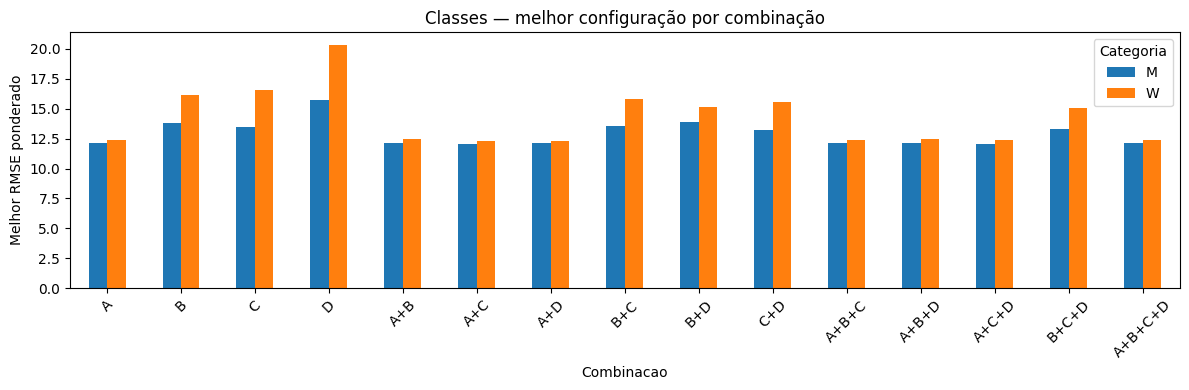

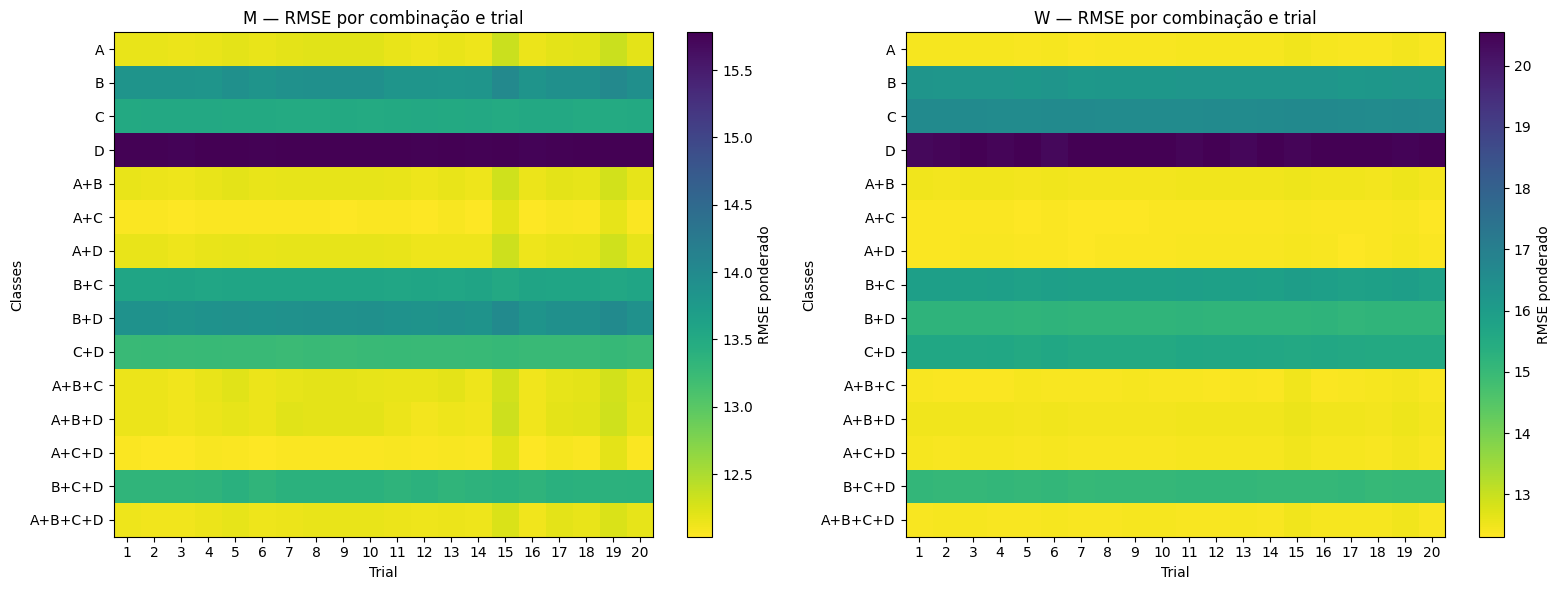

In [8]:
resumo=exp.resumir_combinacoes(ranking)
salvar_tabela('resumo_combinacoes.json',resumo)
if not resumo.empty:
    display(resumo[['Categoria','PosicaoCombinacao','Combinacao','NClasses','NFeatures',
        'Configuracao','ConfiguracoesValidas','RMSE_pond','LB_pond']])
    display(resumo.sort_values(['RMSE_pond','Candidato']).groupby(['Categoria','NClasses']).head(1)[
        ['Categoria','NClasses','Combinacao','NFeatures','Configuracao','RMSE_pond','LB_pond']])
    display(ranking.loc[ranking.Combinacao.isin(['A+B','A+B+C','A+B+C+D']),
        ['Categoria','Configuracao','Combinacao','NFeatures','RMSE_pond','LB_pond']].sort_values(
            ['Categoria','Configuracao','NFeatures']))
    barras=resumo.pivot(index='Combinacao',columns='Categoria',values='RMSE_pond').reindex(tabela_planos.Combinacao)
    barras.plot.bar(figsize=(12,4),ylabel='Melhor RMSE ponderado',title='Classes — melhor configuração por combinação')
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()
    fig,axes=plt.subplots(1,2,figsize=(16,6))
    for ax,cat in zip(axes,['M','W']):
        plot=ranking.loc[ranking.Categoria.eq(cat)].pivot(index='Combinacao',columns='Trial',values='RMSE_pond').reindex(tabela_planos.Combinacao)
        if not len(plot.columns): continue
        im=ax.imshow(plot.to_numpy(dtype=float),aspect='auto',cmap='viridis_r')
        ax.set(title=cat+' — RMSE por combinação e trial',xlabel='Trial',ylabel='Classes',
            xticks=range(len(plot.columns)),xticklabels=plot.columns,yticks=range(15),yticklabels=tabela_planos.Combinacao)
        fig.colorbar(im,ax=ax,label='RMSE ponderado')
    plt.tight_layout(); plt.show()

## Efeito de adicionar uma classe

Comparar X → X+uma classe, mantendo configuração e categoria fixas. Delta negativo
indica melhora após adicionar. São até 28 pares por configuração (1.120 no protocolo
completo). Resultados isolados não demonstram irrelevância de uma classe: possíveis
interações e complementaridades devem ser examinadas em diferentes contextos.


In [9]:
adicoes=exp.comparar_adicoes(ranking)
salvar_tabela('adicoes_classes.json',adicoes)
if not adicoes.empty:
    display(adicoes.loc[adicoes.Antes.isin(['A+B','A+B+C'])&adicoes.Depois.isin(['A+B+C','A+B+C+D'])])
    diagnostico=adicoes.assign(Melhorou=adicoes.Delta_RMSE.lt(0)).groupby(['Categoria','ClasseAdicionada']).agg(
        Pares=('Delta_RMSE','size'),Melhoraram=('Melhorou','sum'),DeltaMedio=('Delta_RMSE','mean'))
    display(diagnostico)
    menores=adicoes.loc[adicoes.MenorFoiMelhor]
    display(HTML('<details><summary>Casos em que menos features tiveram RMSE menor: '+str(len(menores))+
        '</summary>'+menores.to_html(index=False)+'</details>'))
    salvar_tabela('menores_melhores.json',menores)
    print('Médias acima são diagnósticos dos pares, não o critério de seleção do Top 5.')


,Categoria,Configuracao,Antes,Depois,ClasseAdicionada,NFeaturesAntes,NFeaturesDepois,RMSE_antes,RMSE_depois,Delta_RMSE,LB_antes,LB_depois,Delta_LB,MenorFoiMelhor
4,M,M_tabpfn12_06feabfa5be15ec3,A+B+C,A+B+C+D,D,22,26,12.144369,12.133602,-0.010767,0.074378,0.073620,-0.000758,False
7,M,M_tabpfn12_06feabfa5be15ec3,A+B,A+B+C,C,14,22,12.161971,12.144369,-0.017602,0.074292,0.074378,0.000086,False
31,M,M_tabpfn12_0861c6c07c2f35c4,A+B+C,A+B+C+D,D,22,26,12.293612,12.251640,-0.041972,0.071939,0.071267,-0.000673,False
32,M,M_tabpfn12_0861c6c07c2f35c4,A+B,A+B+C,C,14,22,12.301348,12.293612,-0.007735,0.071903,0.071939,0.000036,False
60,M,M_tabpfn12_0e7f98e147911e84,A+B+C,A+B+C+D,D,22,26,12.151895,12.136775,-0.015120,0.074437,0.073451,-0.000986,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1046,W,W_tabpfn12_e5ca5d3fef7485fb,A+B,A+B+C,C,14,22,12.450074,12.397297,-0.052778,0.049805,0.050283,0.000478,False
1066,W,W_tabpfn12_f20bbe99d76118a5,A+B+C,A+B+C+D,D,22,26,12.373219,12.397375,0.024156,0.049900,0.050737,0.000837,True
1073,W,W_tabpfn12_f20bbe99d76118a5,A+B,A+B+C,C,14,22,12.492707,12.373219,-0.119488,0.050411,0.049900,-0.000511,False
1100,W,W_tabpfn12_f4076c2240d6e3c6,A+B+C,A+B+C+D,D,22,26,12.401444,12.403189,0.001745,0.050367,0.050900,0.000534,True


Pares  Melhoraram  DeltaMedio
Categoria ClasseAdicionada                               
M         A                   140         140   -1.748487
          B                   140          44   -0.215579
          C                   140         127   -0.512422
          D                   140         101   -0.070218
W         A                   140         140   -4.011193
          B                   140          71   -0.906266
          C                   140         120   -0.784467
          D                   140          89   -0.401483

Categoria,Configuracao,Antes,Depois,ClasseAdicionada,NFeaturesAntes,NFeaturesDepois,RMSE_antes,RMSE_depois,Delta_RMSE,LB_antes,LB_depois,Delta_LB,MenorFoiMelhor
M,M_tabpfn12_06feabfa5be15ec3,A+C,A+B+C,B,13,22,12.049115,12.144369,0.095254,0.071796,0.074378,0.002582,True
M,M_tabpfn12_06feabfa5be15ec3,A+C,A+C+D,D,13,17,12.049115,12.049324,0.000208,0.071796,0.071110,-0.000686,True
M,M_tabpfn12_06feabfa5be15ec3,A+C+D,A+B+C+D,B,17,26,12.049324,12.133602,0.084279,0.071110,0.073620,0.002510,True
M,M_tabpfn12_06feabfa5be15ec3,C+D,B+C+D,B,12,21,13.245182,13.336558,0.091376,0.088025,0.091294,0.003269,True
M,M_tabpfn12_06feabfa5be15ec3,C,B+C,B,8,17,13.499895,13.578328,0.078433,0.093161,0.096576,0.003415,True
M,M_tabpfn12_06feabfa5be15ec3,B,B+D,D,9,13,13.843390,13.867639,0.024249,0.089948,0.092648,0.002700,True
M,M_tabpfn12_0861c6c07c2f35c4,A+C,A+B+C,B,13,22,12.193843,12.293612,0.099769,0.069574,0.071939,0.002366,True
M,M_tabpfn12_0861c6c07c2f35c4,A+C,A+C+D,D,13,17,12.193843,12.201346,0.007502,0.069574,0.069365,-0.000209,True
M,M_tabpfn12_0861c6c07c2f35c4,A+C+D,A+B+C+D,B,17,26,12.201346,12.251640,0.050294,0.069365,0.071267,0.001902,True
M,M_tabpfn12_0861c6c07c2f35c4,A+B,A+B+D,D,14,18,12.301348,12.321325,0.019977,0.071903,0.071948,0.000045,True


Médias acima são diagnósticos dos pares, não o critério de seleção do Top 5.


## Recursos e registro

Os tempos dos checkpoints reutilizados são históricos. As métricas anuais, erros,
recursos, configurações e features ficam nos checkpoints exclusivos deste experimento.
Não se usam resultados Kaggle para escolher grupos. Os resultados históricos são
de seleção, não uma estimativa independente de generalização.


In [10]:
registros=list(avaliador.estado['avaliacoes'].values())
if registros:
    recursos=pd.DataFrame([{'Categoria':r['Categoria'],'Configuracao':r['Configuracao'],
        'Combinacao':avaliador._plano(r['Features'])['Combinacao'],'Season':c['Season'],
        'status':c['status'],'erro':c.get('erro'),'segundos':0.,**(c.get('recursos') or {})}
        for r in registros for c in r.get('Cortes',[])])
    if not recursos.empty:
        display(recursos.groupby(['Categoria','Configuracao']).agg(Cortes=('Season','size'),Segundos=('segundos','sum')))
        salvar_tabela('recursos.json',recursos)
registro={'features':FEATURES,'classes':exp.CLASSES,'combinacoes':planos,'anos':ANOS,'seed':SEED,'n_folds':5,
    'pesos':REFERENCIAS.to_dict('records'),'candidatos':catalogo,'fontes':manifesto['fontes'],
    'versoes':comum.versoes(),'estado':str(avaliador.path_estado),'max_avaliacoes':MAX_AVALIACOES,
    'piloto':RODAR_PILOTO,'completo':RODAR_COMPLETO,'cobertura_completa':bool(protocolo_completo),
    'busca':manifesto['busca'],'top_k':TOP_K,
    'criterio':'RMSE ponderado; empate pelo ID do candidato'}
comum.salvar_json(CHECKPOINTS/'registro.json',registro)


Cortes    Segundos
Categoria Configuracao                                   
M         M_tabpfn12_06feabfa5be15ec3      45  134.347960
          M_tabpfn12_0861c6c07c2f35c4      45   89.534826
          M_tabpfn12_0e7f98e147911e84      45  248.376401
          M_tabpfn12_1625981a89df3dbc      45   79.753907
          M_tabpfn12_2ccb9a971c426ab1      45   36.210817
          M_tabpfn12_2d0fbd793d895194      45   87.594660
          M_tabpfn12_2f47f428bc93c998      45   64.440271
          M_tabpfn12_32de978635d933eb      45  254.320524
          M_tabpfn12_347709ba70509a9b      45  224.564797
          M_tabpfn12_36abdf9dabab40fa      45   53.207919
          M_tabpfn12_739cd7115f94909f      45   78.175593
          M_tabpfn12_95beaf425161d405      45   39.546733
          M_tabpfn12_a7b7ea3a7de79d09      45  132.582119
          M_tabpfn12_ae91aa07840afde9      45   51.101419
          M_tabpfn12_cb286dfa6bd9d4b6      45  404.225430
          M_tabpfn12_d1eec64c5c3daa7d      45   63.256346
          M_tabpfn12_d6018f884da8d843      45  138.033541
          M_tabpfn12_e5ca5d3fef7485fb      45  240.335106
          M_tabpfn12_f20bbe99d76118a5      45  139.489927
          M_tabpfn12_f4076c2240d6e3c6      45  425.817588
W         W_tabpfn12_06feabfa5be15ec3      45   95.794350
          W_tabpfn12_0861c6c07c2f35c4      45   72.422027
          W_tabpfn12_0e7f98e147911e84      45  173.125647
          W_tabpfn12_1625981a89df3dbc      45   60.065136
          W_tabpfn12_2ccb9a971c426ab1      45   32.618582
          W_tabpfn12_2d0fbd793d895194      45   67.663529
          W_tabpfn12_2f47f428bc93c998      45   54.728524
          W_tabpfn12_32de978635d933eb      45  179.537920
          W_tabpfn12_347709ba70509a9b      45  167.011990
          W_tabpfn12_36abdf9dabab40fa      45   41.366979
          W_tabpfn12_739cd7115f94909f      45   59.091504
          W_tabpfn12_95beaf425161d405      45   32.604904
          W_tabpfn12_a7b7ea3a7de79d09      45  104.215329
          W_tabpfn12_ae91aa07840afde9      45   41.850137
          W_tabpfn12_cb286dfa6bd9d4b6      45  266.432796
          W_tabpfn12_d1eec64c5c3daa7d      45   55.526889
          W_tabpfn12_d6018f884da8d843      45   99.703071
          W_tabpfn12_e5ca5d3fef7485fb      45  157.365858
          W_tabpfn12_f20bbe99d76118a5      45  106.205503
          W_tabpfn12_f4076c2240d6e3c6      45  285.457101

## Cinco submissions de 2026

GERAR_SUBMISSIONS=True retreina os cinco candidatos de M e os cinco de W usando
Season < 2026. Cada posição combina M/W da mesma posição. Margens brutas, sem sigmoid,
IDs/ordem do sample e fallback zero. Os CSVs vão para `submissions/exp15_busca_independente/`;
as três submissions da versão anterior permanecem intactas. Não há envio ao Kaggle.

In [11]:
if GERAR_SUBMISSIONS:
    submissions=exp.gerar_submissions(avaliador,ranking,confrontos,sample,destino=SUBMISSIONS,top_k=TOP_K)
    display(pd.DataFrame(submissions['submissions'])[
        ['Arquivo','CombinacaoM','CombinacaoW','NFeaturesM','NFeaturesW','ConfiguracaoM','ConfiguracaoW','Linhas','IdenticaA']])
    registro['submissions']=submissions
    comum.salvar_json(CHECKPOINTS/'registro.json',registro)
else:
    print('Treino final e geração das cinco submissions desativados.')


,Arquivo,CombinacaoM,CombinacaoW,NFeaturesM,NFeaturesW,ConfiguracaoM,ConfiguracaoW,Linhas,IdenticaA
0,submission_exp15_tabpfn_rmse_top1_2026.csv,A+C,A+D,13,9,M_tabpfn12_2ccb9a971c426ab1,W_tabpfn12_d1eec64c5c3daa7d,132133,None
1,submission_exp15_tabpfn_rmse_top2_2026.csv,A+C,A+C,13,13,M_tabpfn12_1625981a89df3dbc,W_tabpfn12_2d0fbd793d895194,132133,None
2,submission_exp15_tabpfn_rmse_top3_2026.csv,A+C+D,A+C,17,13,M_tabpfn12_1625981a89df3dbc,W_tabpfn12_e5ca5d3fef7485fb,132133,None
3,submission_exp15_tabpfn_rmse_top4_2026.csv,A+C+D,A+D,17,9,M_tabpfn12_36abdf9dabab40fa,W_tabpfn12_2f47f428bc93c998,132133,None
4,submission_exp15_tabpfn_rmse_top5_2026.csv,A+C,A+C,13,13,M_tabpfn12_32de978635d933eb,W_tabpfn12_d1eec64c5c3daa7d,132133,None
